In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import matplotlib.pyplot as plt

In [ ]:
import os

project_dir = "/content/mnist_assignment"

os.makedirs(project_dir, exist_ok=True)

os.chdir(project_dir)

print("Current directory:", os.getcwd())

Current directory: /content/mnist_assignment


data augmentation- two transforms:Why? A handwritten 7 may be slightly rotated or shifted and still be a 7. This helps your CNN generalize from only 256 images.

In [ ]:
train_transform = transforms.Compose([
    transforms.RandomRotation(10),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1)
    ),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

The ZIP you uploaded doesn't appear to contain the MNIST data itself, but PyTorch can download it automatically.


In [ ]:
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))

Training images: 60000
Test images: 10000


“The assignment limits the training set to 256 images, so I randomly selected 256 samples from MNIST. I used a fixed random seed to make the selection reproducible, meaning the same 256 training images are selected every time the notebook runs.”

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

**The next step is to build the CNN, train it, and evaluate it**

```
Input:          1 × 28 × 28
                     ↓
Conv:          32 × 28 × 28
                     ↓
MaxPool:       32 × 14 × 14
                     ↓
Conv:          64 × 14 × 14
                     ↓
MaxPool:       64 × 7 × 7
                     ↓
Flatten:       3136

```







In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
torch.manual_seed(42)
model = CNN()

print(model)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


“I created an instance of my CNN architecture so I can train it.”

In [ ]:
from collections import Counter

labels = [full_train_dataset[i][1] for i in indices.tolist()]

print(Counter(labels))

Counter({6: 38, 2: 31, 9: 28, 1: 27, 0: 25, 7: 24, 4: 23, 3: 23, 5: 19, 8: 18})


“I randomly selected 256 images from the MNIST training set using a fixed seed for reproducibility. I also checked the class distribution and confirmed that all 10 digits are represented.”

In [ ]:
criterion = nn.CrossEntropyLoss()
#“I used CrossEntropyLoss because this is a multi-class classification problem with 10 digit classes.”

In [ ]:
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
#“I used Adam to update the model parameters based on the gradients, with a learning rate of 0.001.”

In [ ]:
num_epochs = 5

train_losses = []

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)
    train_losses.append(average_loss)

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Loss: {average_loss:.4f}"
    )

Epoch [1/5], Loss: 0.1884
Epoch [2/5], Loss: 0.0499
Epoch [3/5], Loss: 0.0337
Epoch [4/5], Loss: 0.0261
Epoch [5/5], Loss: 0.0199


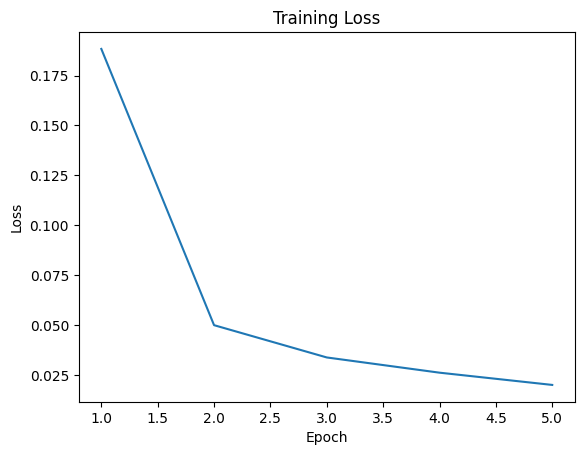

In [ ]:
plt.plot(range(1, num_epochs + 1), train_losses)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.show()

Ideally, you'll see the loss generally going downward. That tells you the model is learning the training data.

In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 99.05%


“I'm testing, not training, so don't calculate gradients.”